In [ ]:
import torch

# The same GPT-2 output distribution p(w | "Hello world, nice to") from above, top 10 of 50257 words
# (renormalized so this top-10 slice sums to 1)
vocab = ["see", "meet", "hear", "have", "be", "know", "you", "talk", "say", "get"]
probs = torch.tensor([0.387361, 0.154993, 0.152304, 0.127857, 0.057572, 0.043027, 0.039115, 0.015646, 0.013935, 0.008190])

print("Asking GPT-2 what is p(y|Hello world, nice to):")
for i in torch.argsort(probs, descending=True):
    print(f"{vocab[i]} : {probs[i]:.4f}")
print(f"Total sum of p(y|Hello world, nice to): {probs.sum():.4f}")

Asking GPT-2 what is p(w|Hello world, nice to):
see : 0.3874
meet : 0.1550
hear : 0.1523
have : 0.1279
be : 0.0576
know : 0.0430
you : 0.0391
talk : 0.0156
say : 0.0139
get : 0.0082
Total sum of p(w|Hello world, nice to): 1.0000


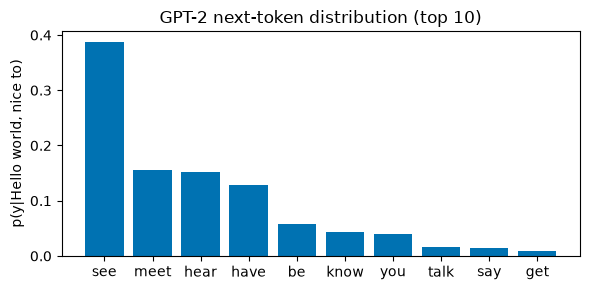

In [ ]:
import matplotlib.pyplot as plt

order = torch.argsort(probs, descending=True)
plt.figure(figsize=(6, 3))
plt.bar([vocab[i] for i in order], probs[order], color="#0072B2")
plt.ylabel("p(y|Hello world, nice to)")
plt.title("GPT-2 next-token distribution (top 10)")
plt.tight_layout()
plt.show()

In [ ]:
g = torch.Generator()

n = 10_000_000
target_e = "see"

# p must normalize to 1, so we renormalize our top-10 slice of the distribution
p = probs / probs.sum()
# draw all n samples at once, according to p(y|"Hello world, nice to")
# (tensors hold numbers, not strings, so we sample vocab indices rather than words)
outcomes = torch.multinomial(p, n, replacement=True, generator=g)

i_e = vocab.index(target_e)
prob_e = p[i_e].item()
freq_e = (outcomes == i_e).float().mean().item()
print(f"the expected probability of \"{target_e}\" is {prob_e}")
print(f"the actual frequency of \"{target_e}\" in {n} trials is {freq_e}")

the expected probability of "see" is 0.38736099004745483
the actual frequency of "see" in 10000000 trials is 0.38721099495887756


In [ ]:
print("gpt-2's output distribution is stored with a torch.Tensor rather than a vanilla python list")
print(f"probs.shape {type(probs.shape)}: {probs.shape}")
print(f"probs.dtype {type(probs.dtype)}: {probs.dtype}")

print("\ngpt-2's individual probabilities are accessed by indexing into")
print(f'0 ({vocab[0]}) -> {probs[0]}')
print(f'1 ({vocab[1]}) -> {probs[1]}')
print(f'2 ({vocab[2]}) -> {probs[2]}')

gpt-2's output distribution is stored with a torch.Tensor rather than a vanilla python list
probs.shape <class 'torch.Size'>: torch.Size([10])
probs.dtype <class 'torch.dtype'>: torch.float32
gpt-2's individual probabilities are accessed by indexing into
0 (see) -> 0.38736099004745483
1 (meet) -> 0.1549929976463318
2 (hear) -> 0.15230399370193481


In [ ]:
# events are subsets of outcomes, represented as boolean masks over the vocabulary
starts_with_h = torch.tensor([w.startswith("h") for w in vocab])
starts_with_s = torch.tensor([w.startswith("s") for w in vocab])
contains_a = torch.tensor(["a" in w for w in vocab])

# the probability of an event is the sum of probabilities of the outcomes it contains
prob_h = probs[starts_with_h].sum()
prob_s = probs[starts_with_s].sum()
prob_h_or_s = probs[starts_with_h | starts_with_s].sum()
prob_h_or_s_and_a = probs[(starts_with_h | starts_with_s) & contains_a].sum()

print(f"probability that word starts with letter h: {prob_h:.4f}")
print(f"probability that word starts with letter s: {prob_s:.4f}")
print(f"probability that word starts with letter h or s: {prob_h_or_s:.4f}")
print(f"probability that word starts with letter h or s, and contains letter a: {prob_h_or_s_and_a:.4f}")

In [ ]:
import torch

# The same <span class="smallcaps">GPT-2</span> output distribution p(w | "Hello world, nice to") from above, top 10 of 50257 words
tokens = ["see", "meet", "hear", "have", "be", "know", "you", "talk", "say", "get"]
probs = torch.tensor([0.3169, 0.1268, 0.1246, 0.1046, 0.0471, 0.0352, 0.0320, 0.0128, 0.0114, 0.0067])

tokens_start_with_h_or_s_and_contains_a_probs = []
for token, prob in zip(tokens, probs):
    stripped = token.strip()
    starts_with_h = stripped.startswith("h")
    starts_with_s = stripped.startswith("s")
    contains_a = "a" in stripped
    if (starts_with_h or starts_with_s) and contains_a:
        tokens_start_with_h_or_s_and_contains_a_probs.append(prob)

prob_starts_with_h_or_s_and_contains_a = sum(tokens_start_with_h_or_s_and_contains_a_probs)

print(f"probability that word starts with letter h: {prob_starts_with_h}")
print(f"probability that word starts with letter s: {prob_starts_with_s}")
print(f"probability that word starts with letter h or s: {prob_starts_with_h + prob_starts_with_s}")
print(f"probability that word starts with letter h or s, and contains letter a: {prob_starts_with_h_or_s_and_contains_a}")
